<a href="https://colab.research.google.com/github/moiz-shahid/Deep-Learning-Tutorials/blob/main/Tutorial-12-Basic-Autoencoders/DL_Tutorial_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import random
import copy

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch Version:", torch.__version__)
print("Device:", device)

PyTorch Version: 2.14.1+cu130
Device: cuda


In [2]:
transform = transforms.ToTensor()

full_train_dataset = datasets.MNIST(
    root="/content/mnist_data",
    train=True,
    transform=transform,
    download=True
)

test_dataset = datasets.MNIST(
    root="/content/mnist_data",
    train=False,
    transform=transform,
    download=True
)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [54000, 6000],
    generator=torch.Generator().manual_seed(42)
)

batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

images, labels = next(iter(train_loader))

print("Input tensor shape:", images.shape)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.59MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.05MB/s]

Training images: 54000
Validation images: 6000
Test images: 10000


Input tensor shape: torch.Size([128, 1, 28, 28])


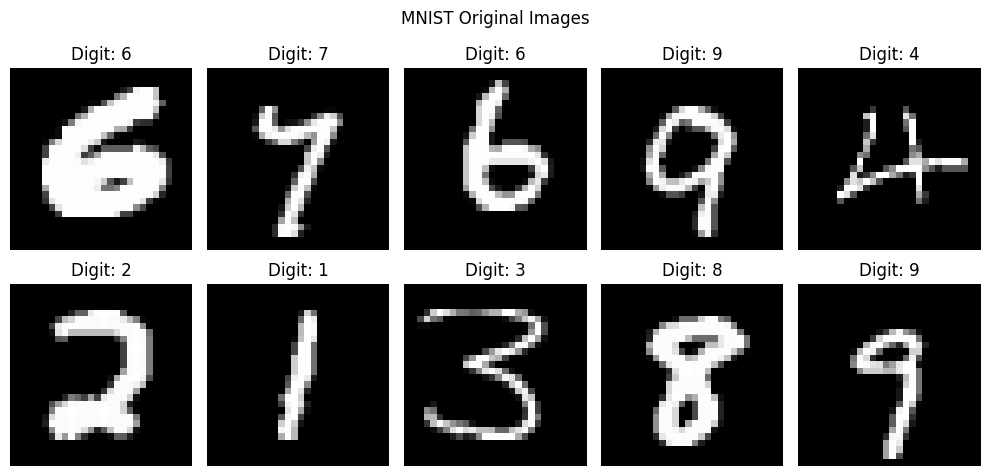

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):

    image, label = train_dataset[i]

    ax.imshow(
        image.squeeze().numpy(),
        cmap="gray"
    )

    ax.set_title(f"Digit: {label}")
    ax.axis("off")

plt.suptitle("MNIST Original Images")
plt.tight_layout()
plt.show()

In [4]:
class BasicAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(

            nn.Conv2d(
                1, 32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                32, 64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.MaxPool2d(2)
        )

        # Decoder
        self.decoder = nn.Sequential(

            nn.Conv2d(
                64, 64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.Upsample(scale_factor=2, mode="nearest"),

            nn.Conv2d(
                64, 32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.Upsample(scale_factor=2, mode="nearest"),

            nn.Conv2d(
                32, 1,
                kernel_size=3,
                padding=1
            ),
            nn.Sigmoid()
        )

    def forward(self, x):

        encoded = self.encoder(x)

        decoded = self.decoder(encoded)

        return decoded


model = BasicAutoencoder().to(device)

print(model)

BasicAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Upsample(scale_factor=2.0, mode='nearest')
    (3): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): Upsample(scale_factor=2.0, mode='nearest')
    (6): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): Sigmoid()
  )
)


In [5]:
dummy_input = torch.randn(
    1, 1, 28, 28
).to(device)

model.eval()

with torch.no_grad():

    encoded = model.encoder(dummy_input)

    reconstructed = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Encoded shape:", encoded.shape)
print("Reconstructed shape:", reconstructed.shape)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", f"{total_params:,}")

Input shape: torch.Size([1, 1, 28, 28])
Encoded shape: torch.Size([1, 64, 7, 7])
Reconstructed shape: torch.Size([1, 1, 28, 28])
Total parameters: 74,497


In [6]:
def train_autoencoder(
    model,
    train_loader,
    val_loader,
    epochs=50,
    lr=0.001
):

    criterion = nn.BCELoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_weights = None
    best_epoch = 0

    for epoch in range(epochs):

        # Training
        model.train()
        train_loss_total = 0

        for images, _ in train_loader:

            images = images.to(device)

            optimizer.zero_grad()

            reconstructed = model(images)

            loss = criterion(
                reconstructed,
                images
            )

            loss.backward()
            optimizer.step()

            train_loss_total += (
                loss.item() * images.size(0)
            )

        avg_train_loss = (
            train_loss_total / len(train_loader.dataset)
        )

        # Validation
        model.eval()
        val_loss_total = 0

        with torch.no_grad():

            for images, _ in val_loader:

                images = images.to(device)

                reconstructed = model(images)

                loss = criterion(
                    reconstructed,
                    images
                )

                val_loss_total += (
                    loss.item() * images.size(0)
                )

        avg_val_loss = (
            val_loss_total / len(val_loader.dataset)
        )

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)

        if avg_val_loss < best_val_loss:

            best_val_loss = avg_val_loss

            best_weights = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch + 1

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss: {avg_train_loss:.5f} | "
            f"Val Loss: {avg_val_loss:.5f}"
        )

    model.load_state_dict(best_weights)

    print("\nBest Epoch:", best_epoch)
    print("Best Validation Loss:", round(best_val_loss, 5))

    return model, history

In [7]:
torch.manual_seed(42)

model = BasicAutoencoder().to(device)

model, history = train_autoencoder(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=50,
    lr=0.001
)

Epoch 01/50 | Train Loss: 0.11619 | Val Loss: 0.07534
Epoch 02/50 | Train Loss: 0.07314 | Val Loss: 0.07147
Epoch 03/50 | Train Loss: 0.07052 | Val Loss: 0.07014
Epoch 04/50 | Train Loss: 0.06907 | Val Loss: 0.06852
Epoch 05/50 | Train Loss: 0.06808 | Val Loss: 0.06794
Epoch 06/50 | Train Loss: 0.06739 | Val Loss: 0.06730
Epoch 07/50 | Train Loss: 0.06683 | Val Loss: 0.06654
Epoch 08/50 | Train Loss: 0.06638 | Val Loss: 0.06651
Epoch 09/50 | Train Loss: 0.06602 | Val Loss: 0.06587
Epoch 10/50 | Train Loss: 0.06568 | Val Loss: 0.06551
Epoch 11/50 | Train Loss: 0.06542 | Val Loss: 0.06524
Epoch 12/50 | Train Loss: 0.06516 | Val Loss: 0.06515
Epoch 13/50 | Train Loss: 0.06494 | Val Loss: 0.06485
Epoch 14/50 | Train Loss: 0.06473 | Val Loss: 0.06467
Epoch 15/50 | Train Loss: 0.06455 | Val Loss: 0.06450
Epoch 16/50 | Train Loss: 0.06438 | Val Loss: 0.06443
Epoch 17/50 | Train Loss: 0.06425 | Val Loss: 0.06484
Epoch 18/50 | Train Loss: 0.06410 | Val Loss: 0.06437
Epoch 19/50 | Train Loss: 0.

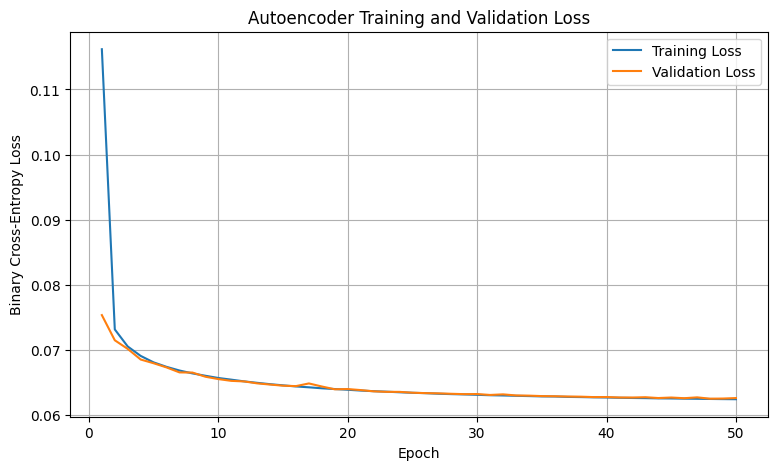

In [8]:
epochs_range = range(
    1, len(history["train_loss"]) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Autoencoder Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
model.eval()

bce_criterion = nn.BCELoss(reduction="sum")
mse_criterion = nn.MSELoss(reduction="sum")

total_bce = 0
total_mse = 0
total_pixels = 0

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(device)

        reconstructed = model(images)

        total_bce += bce_criterion(
            reconstructed, images
        ).item()

        total_mse += mse_criterion(
            reconstructed, images
        ).item()

        total_pixels += images.numel()

test_bce = total_bce / total_pixels
test_mse = total_mse / total_pixels

print("FINAL TEST RESULTS")
print("-" * 40)

print(f"Test BCE Loss: {test_bce:.6f}")
print(f"Test MSE: {test_mse:.6f}")

FINAL TEST RESULTS
----------------------------------------
Test BCE Loss: 0.062099
Test MSE: 0.000911


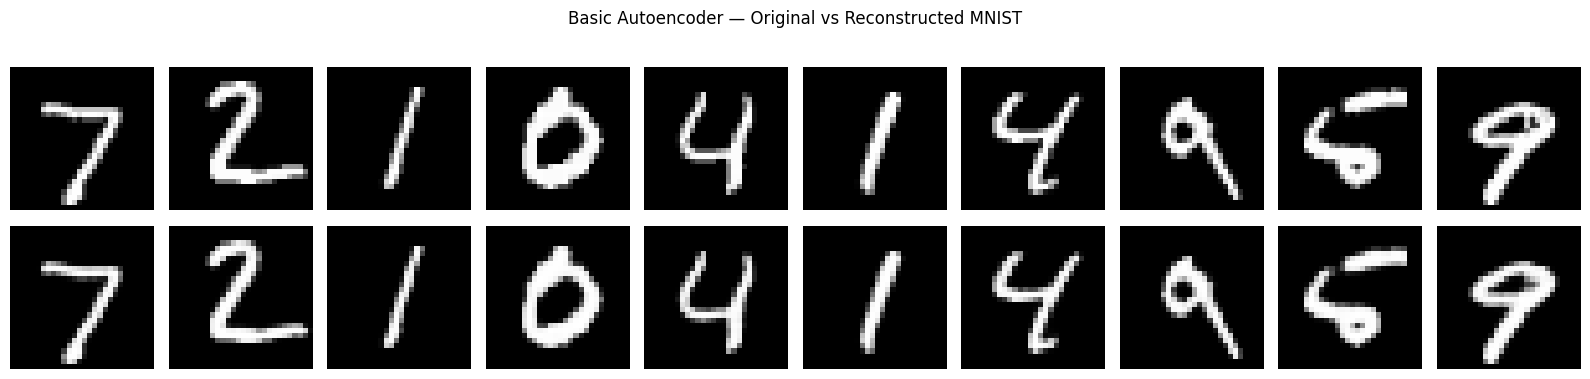

In [10]:
model.eval()

images, labels = next(iter(test_loader))

images = images[:10].to(device)

with torch.no_grad():
    reconstructed = model(images)

original_images = images.cpu().numpy()
reconstructed_images = reconstructed.cpu().numpy()

fig, axes = plt.subplots(2, 10, figsize=(16, 4))

for i in range(10):

    # Original
    axes[0, i].imshow(
        original_images[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[0, i].axis("off")

    # Reconstructed
    axes[1, i].imshow(
        reconstructed_images[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, i].axis("off")

axes[0, 0].set_ylabel(
    "Original",
    fontsize=12
)

axes[1, 0].set_ylabel(
    "Reconstructed",
    fontsize=12
)

plt.suptitle(
    "Basic Autoencoder — Original vs Reconstructed MNIST"
)

plt.tight_layout()
plt.show()

In [11]:
import os

save_dir = "/content/tutorial12_results"

os.makedirs(
    save_dir,
    exist_ok=True
)

torch.save(
    model.state_dict(),
    f"{save_dir}/basic_autoencoder.pth"
)

history_df = pd.DataFrame(history)

history_df.to_csv(
    f"{save_dir}/basic_autoencoder_history.csv",
    index=False
)

results_df = pd.DataFrame([{
    "Model": "Basic Autoencoder",
    "Test BCE": test_bce,
    "Test MSE": test_mse,
    "Parameters": total_params
}])

results_df.to_csv(
    f"{save_dir}/basic_autoencoder_results.csv",
    index=False
)

display(results_df)

print("Model and experiment results saved.")

,Model,Test BCE,Test MSE,Parameters
0,Basic Autoencoder,0.062099,0.000911,74497


Model and experiment results saved.


## Analysis

Training and validation losses decreased consistently, demonstrating that the model successfully learned to reconstruct MNIST images.

The validation loss reached its minimum of 0.06250 at epoch 48. The training and validation curves remained close throughout the experiment, with no clear evidence of overfitting.

The test BCE loss of 0.062099 and MSE of 0.000911 indicate a low reconstruction error.

Visual inspection showed that the reconstructed handwritten digits closely resembled the original images. The overall digit structures and strokes were preserved, although some reconstructed edges appeared slightly smoother.

The encoder reduced the spatial resolution of the input from 28×28 to 7×7 while increasing the number of feature channels to 64. Consequently, the latent tensor contained more scalar values than the input image, even though its spatial dimensions were smaller.

## Improving the Autoencoder Architecture

In [12]:
class ImprovedAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(

            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(

            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.ConvTranspose2d(
                64, 64,
                kernel_size=2,
                stride=2
            ),
            nn.ReLU(),

            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 32,
                kernel_size=2,
                stride=2
            ),
            nn.ReLU(),

            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):

        encoded = self.encoder(x)
        decoded = self.decoder(encoded)

        return decoded


improved_model = ImprovedAutoencoder().to(device)

print(improved_model)

ImprovedAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU()
    (9): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (14): ReLU()
  )
  (decoder): Sequenti

In [13]:
dummy_input = torch.randn(1, 1, 28, 28).to(device)

improved_model.eval()

with torch.no_grad():

    encoded = improved_model.encoder(dummy_input)
    reconstructed = improved_model(dummy_input)

print("Input:", dummy_input.shape)
print("Encoded:", encoded.shape)
print("Reconstructed:", reconstructed.shape)

basic_params = sum(
    p.numel() for p in model.parameters()
)

improved_params = sum(
    p.numel() for p in improved_model.parameters()
)

print("\nBasic Model Parameters:", f"{basic_params:,}")
print("Improved Model Parameters:", f"{improved_params:,}")

Input: torch.Size([1, 1, 28, 28])
Encoded: torch.Size([1, 128, 7, 7])
Reconstructed: torch.Size([1, 1, 28, 28])

Basic Model Parameters: 74,497
Improved Model Parameters: 252,609


In [14]:
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

improved_model = ImprovedAutoencoder().to(device)

improved_model, improved_history = train_autoencoder(
    model=improved_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=50,
    lr=0.001
)

Epoch 01/50 | Train Loss: 0.12964 | Val Loss: 0.07332
Epoch 02/50 | Train Loss: 0.06490 | Val Loss: 0.06432
Epoch 03/50 | Train Loss: 0.06366 | Val Loss: 0.06526
Epoch 04/50 | Train Loss: 0.06291 | Val Loss: 0.06290
Epoch 05/50 | Train Loss: 0.06243 | Val Loss: 0.06232
Epoch 06/50 | Train Loss: 0.06216 | Val Loss: 0.06227
Epoch 07/50 | Train Loss: 0.06189 | Val Loss: 0.06251
Epoch 08/50 | Train Loss: 0.06165 | Val Loss: 0.06178
Epoch 09/50 | Train Loss: 0.06145 | Val Loss: 0.06171
Epoch 10/50 | Train Loss: 0.06130 | Val Loss: 0.06136
Epoch 11/50 | Train Loss: 0.06106 | Val Loss: 0.06145
Epoch 12/50 | Train Loss: 0.06099 | Val Loss: 0.06107
Epoch 13/50 | Train Loss: 0.06085 | Val Loss: 0.06106
Epoch 14/50 | Train Loss: 0.06077 | Val Loss: 0.06081
Epoch 15/50 | Train Loss: 0.06061 | Val Loss: 0.06071
Epoch 16/50 | Train Loss: 0.06059 | Val Loss: 0.06074
Epoch 17/50 | Train Loss: 0.06047 | Val Loss: 0.06066
Epoch 18/50 | Train Loss: 0.06038 | Val Loss: 0.06061
Epoch 19/50 | Train Loss: 0.

In [15]:
def evaluate_autoencoder(model, data_loader):

    model.eval()

    bce_criterion = nn.BCELoss(reduction="sum")
    mse_criterion = nn.MSELoss(reduction="sum")

    total_bce = 0
    total_mse = 0
    total_pixels = 0

    with torch.no_grad():

        for images, _ in data_loader:

            images = images.to(device)

            reconstructed = model(images)

            total_bce += bce_criterion(
                reconstructed, images
            ).item()

            total_mse += mse_criterion(
                reconstructed, images
            ).item()

            total_pixels += images.numel()

    return {
        "BCE": total_bce / total_pixels,
        "MSE": total_mse / total_pixels
    }


basic_metrics = evaluate_autoencoder(
    model,
    test_loader
)

improved_metrics = evaluate_autoencoder(
    improved_model,
    test_loader
)

print("BASIC AUTOENCODER")
print(basic_metrics)

print("\nIMPROVED AUTOENCODER")
print(improved_metrics)

BASIC AUTOENCODER
{'BCE': 0.06209855331109495, 'MSE': 0.0009112885973891434}

IMPROVED AUTOENCODER
{'BCE': 0.05935745272733727, 'MSE': 0.00029575017289239534}


In [16]:
comparison_df = pd.DataFrame({

    "Model": [
        "Basic Autoencoder",
        "Improved Autoencoder"
    ],

    "Parameters": [
        basic_params,
        improved_params
    ],

    "Test BCE": [
        basic_metrics["BCE"],
        improved_metrics["BCE"]
    ],

    "Test MSE": [
        basic_metrics["MSE"],
        improved_metrics["MSE"]
    ]

})

display(comparison_df.round(6))

bce_improvement = (
    (basic_metrics["BCE"] - improved_metrics["BCE"])
    / basic_metrics["BCE"] * 100
)

mse_improvement = (
    (basic_metrics["MSE"] - improved_metrics["MSE"])
    / basic_metrics["MSE"] * 100
)

print(f"BCE reduction: {bce_improvement:.2f}%")
print(f"MSE reduction: {mse_improvement:.2f}%")

,Model,Parameters,Test BCE,Test MSE
0,Basic Autoencoder,74497,0.062099,0.000911
1,Improved Autoencoder,252609,0.059357,0.000296


BCE reduction: 4.41%
MSE reduction: 67.55%


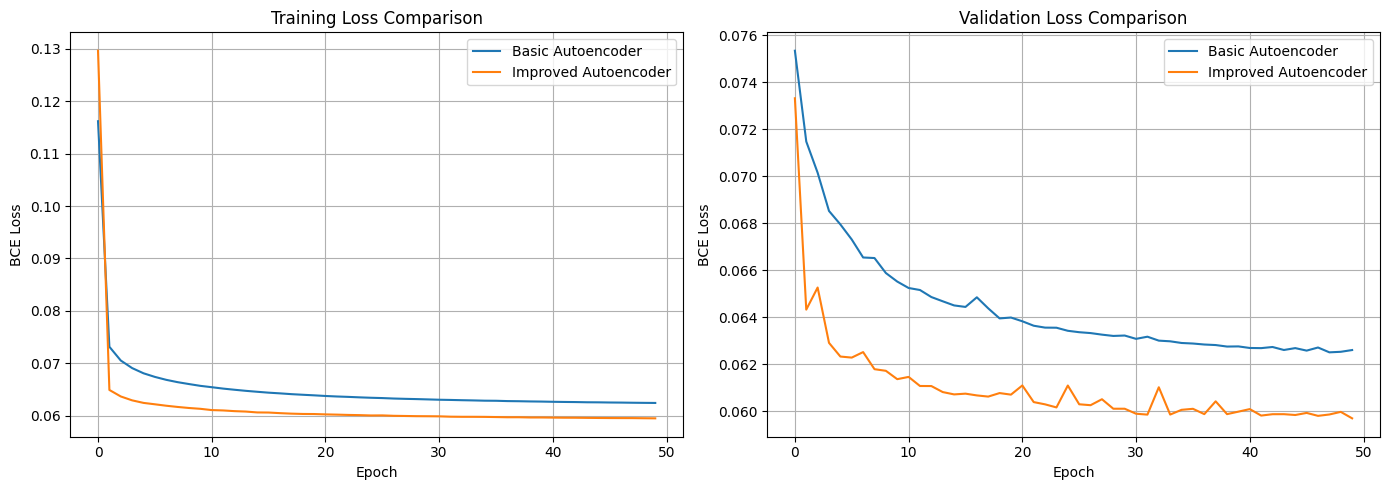

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training loss
axes[0].plot(
    history["train_loss"],
    label="Basic Autoencoder"
)

axes[0].plot(
    improved_history["train_loss"],
    label="Improved Autoencoder"
)

axes[0].set_title("Training Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE Loss")
axes[0].legend()
axes[0].grid(True)


# Validation loss
axes[1].plot(
    history["val_loss"],
    label="Basic Autoencoder"
)

axes[1].plot(
    improved_history["val_loss"],
    label="Improved Autoencoder"
)

axes[1].set_title("Validation Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("BCE Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

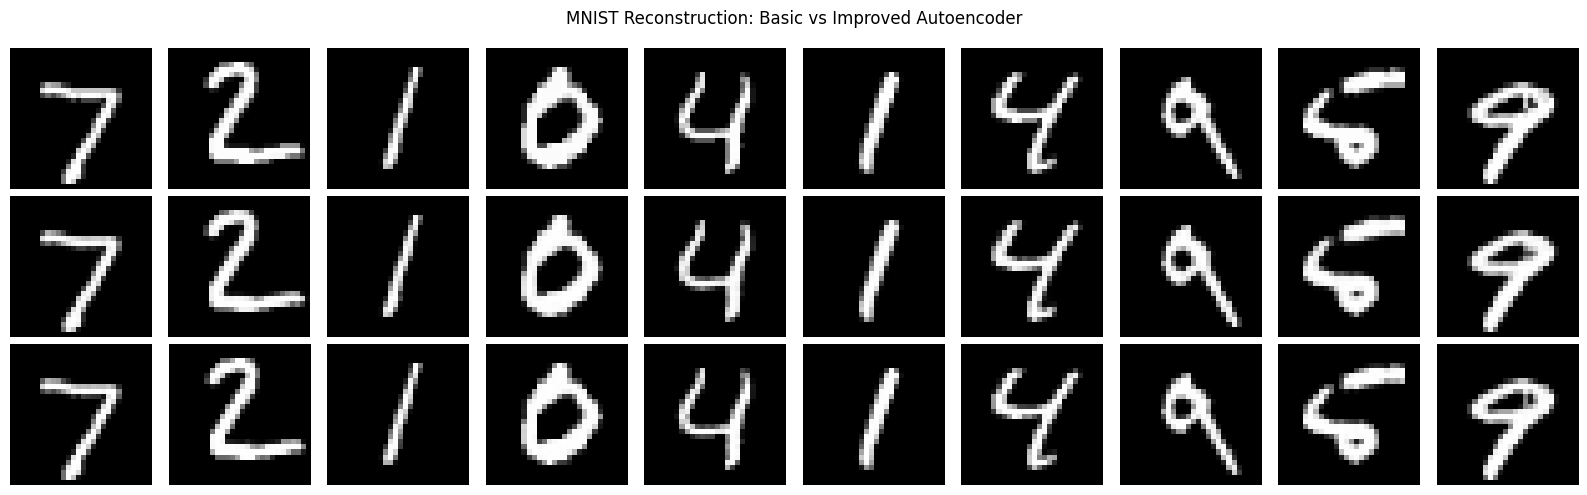

In [18]:
model.eval()
improved_model.eval()

images, labels = next(iter(test_loader))

images = images[:10].to(device)

with torch.no_grad():

    basic_recon = model(images)
    improved_recon = improved_model(images)

original_np = images.cpu().numpy()
basic_np = basic_recon.cpu().numpy()
improved_np = improved_recon.cpu().numpy()

fig, axes = plt.subplots(3, 10, figsize=(16, 5))

for i in range(10):

    axes[0, i].imshow(
        original_np[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, i].imshow(
        basic_np[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[2, i].imshow(
        improved_np[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    for j in range(3):
        axes[j, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=11)
axes[1, 0].set_ylabel("Basic", fontsize=11)
axes[2, 0].set_ylabel("Improved", fontsize=11)

plt.suptitle(
    "MNIST Reconstruction: Basic vs Improved Autoencoder"
)

plt.tight_layout()
plt.show()

In [19]:
import os

save_dir = "/content/tutorial12_improved_results"

os.makedirs(save_dir, exist_ok=True)

# Save improved model
torch.save(
    improved_model.state_dict(),
    f"{save_dir}/improved_autoencoder.pth"
)

# Save training history
pd.DataFrame(
    improved_history
).to_csv(
    f"{save_dir}/improved_training_history.csv",
    index=False
)

# Save final model comparison
comparison_df.to_csv(
    f"{save_dir}/autoencoder_comparison.csv",
    index=False
)

# Save reconstruction comparison figure
fig.savefig(
    f"{save_dir}/reconstruction_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

print("Experiment results saved successfully.")

display(comparison_df.round(6))

Experiment results saved successfully.


,Model,Parameters,Test BCE,Test MSE
0,Basic Autoencoder,74497,0.062099,0.000911
1,Improved Autoencoder,252609,0.059357,0.000296
